In [1]:
#준비 셀 1. 데이터, 한 줄 추가
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.deterministic = True # 새 줄, GPU에서도 같은 seed면 같은 결과
train_all = datasets.MNIST(root="data", train=True, download=True,
 transform=transforms.ToTensor())
g = torch.Generator().manual_seed(0) # 학습과 검증 분리, seed 0
train_set, val_set = random_split(train_all, [50000, 10000], generator=g)
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
val_loader = DataLoader(val_set, batch_size=256, shuffle=False)
print(len(train_loader), len(val_loader)) # → 782 40

100.0%
100.0%
100.0%
100.0%

782 40


In [3]:
#준비 셀 2. Baseline MLP와 loss_fn
class MLP(nn.Module): # Baseline MLP 그대로
 def __init__(self):
    super().__init__()
    self.flat = nn.Flatten() # (N, 1, 28, 28) → (N, 784)
    self.fc1 = nn.Linear(784, 100)
    self.act = nn.ReLU()
    self.fc2 = nn.Linear(100, 10)
 def forward(self, x):
    x = self.flat(x)
    return self.fc2(self.act(self.fc1(x)))
loss_fn = nn.CrossEntropyLoss()
print(MLP()(torch.zeros(2, 1, 28, 28)).shape) # → torch.Size([2, 10])

torch.Size([2, 10])


In [5]:
#준비 셀 3-1. 검증 함수
def evaluate(model, loader): # 검증 함수, 그대로
 model.eval()
 total_loss, correct = 0.0, 0
 with torch.no_grad():
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        total_loss += loss_fn(out, y).item() * len(y)
        correct += (out.argmax(dim=1) == y).sum().item()
 n = len(loader.dataset)
 return total_loss / n, correct / n * 100

In [4]:
#준비 셀 3-2. 학습 함수
def train_one_epoch(model, loader, opt): # 학습 함수, 그대로
 model.train()
 total_loss = 0.0
 for x, y in loader:
    x, y = x.to(device), y.to(device)
    loss = loss_fn(model(x), y)
    opt.zero_grad()
    loss.backward()
    opt.step()
    total_loss += loss.item() * len(y)
 return total_loss / len(loader.dataset)

In [6]:
#예제 5-1. 세로 경계 kernel과 가로 경계 kernel
import torch.nn.functional as F
img, label = train_all[0] # 첫 번째 학습 사진 (1, 28, 28)
x = img.view(1, 1, 28, 28) # (N, C, H, W), 1장짜리 배치
k_v = torch.tensor([[-1., 0., 1.],
 [-1., 0., 1.],
 [-1., 0., 1.]]) # 세로 경계 kernel
k_h = torch.tensor([[-1., -1., -1.],
 [ 0., 0., 0.],
 [ 1., 1., 1.]]) # 가로 경계 kernel
out_v = F.conv2d(x, k_v.view(1, 1, 3, 3)) # kernel 모양도 4차원
out_h = F.conv2d(x, k_h.view(1, 1, 3, 3))
print(label, x.shape) # → 5 torch.Size([1, 1, 28, 28])
print(out_v.shape) # → torch.Size([1, 1, 26, 26])

5 torch.Size([1, 1, 28, 28])
torch.Size([1, 1, 26, 26])


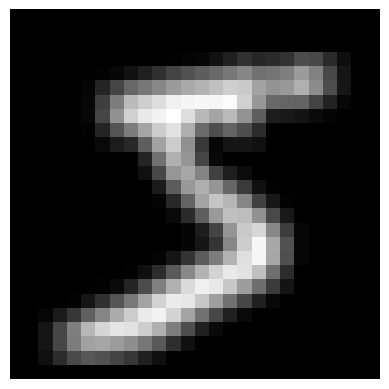

In [8]:
from matplotlib import pyplot as plt

#실습 1 셀. 첫 줄만 바꿔 가며 실행
k = torch.ones(3, 3) / 9 # 이 줄의 kernel만 바꿔 가며 실행한다
out = F.conv2d(x, k.view(1, 1, 3, 3)) # 예제 5-1의 사진 x에 적용
plt.imshow(out[0, 0], cmap="gray")
plt.axis("off")
plt.show()

In [9]:
#실습 1. 정답 예시, 실습 1 셀의 첫 줄을 셋 중 하나로 (한 번에 하나씩)
k = torch.ones(3, 3) / 9 # 1. 9칸 모두 1/9, 주변 평균
k = torch.tensor([[0., 0., 0.],
 [0., 1., 0.],
 [0., 0., 0.]]) # 2. 가운데만 1
k = torch.tensor([[ 0., 1., 1.],
 [-1., 0., 1.],
 [-1., -1., 0.]]) # 3. 대각선 경계, 한 가지 예

In [10]:
#예제 5-2. 학습할 kernel 16개를 가진 계층
conv = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3)
print(conv.weight.shape) # → torch.Size([16, 1, 3, 3]) (3×3 kernel 16개)
print(conv.bias.shape) # → torch.Size([16])
print(sum(p.numel() for p in conv.parameters())) # → 160 (16 × 9 + 16)
x, y = next(iter(train_loader)) # 배치 하나
print(x.shape) # → torch.Size([64, 1, 28, 28]) (N, C, H, W)
print(conv(x).shape) # → torch.Size([64, 16, 26, 26]) (feature map 16장씩)

torch.Size([16, 1, 3, 3])
torch.Size([16])
160
torch.Size([64, 1, 28, 28])
torch.Size([64, 16, 26, 26])


In [11]:
#예제 5-3. 컬러 사진 모양 (1, 3, 32, 32)에 적용
conv_rgb = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3)
print(conv_rgb.weight.shape) # → torch.Size([16, 3, 3, 3]) (kernel 16개, 두께 3)
print(sum(p.numel() for p in conv_rgb.parameters())) # → 448 (16 × 27 + 16)
photo = torch.rand(1, 3, 32, 32) # 컬러 사진 1장 모양, 값은 무작위
print(conv_rgb(photo).shape) # → torch.Size([1, 16, 30, 30])

torch.Size([16, 3, 3, 3])
448
torch.Size([1, 16, 30, 30])


In [12]:
#2와 3을 실행해서 검증
print(sum(p.numel() for p in nn.Linear(784, 100).parameters()))
# → 78500 (문제 2, 28×28)
print(sum(p.numel() for p in nn.Linear(280 * 280, 100).parameters()))
# → 7840100 (문제 2, 280×280, 약 100배)
print(sum(p.numel() for p in nn.Conv2d(1, 16, 3).parameters()))
# → 160 (문제 2, 사진 크기와 상관없다)
flat = torch.full((1, 1, 5, 5), 0.7) # 3. 고르게 0.7인 사진
print(F.conv2d(flat, k_v.view(1, 1, 3, 3)).view(-1).tolist())
# → [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
print(k_v.sum().item()) # → 0.0 (kernel 값의 합)

78500
7840100
160
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
0.0


In [13]:
#예제 5-4. 같은 사진, 다른 설정 세 가지
x = torch.zeros(1, 1, 28, 28) # 사진 1장 모양
conv_a = nn.Conv2d(1, 8, kernel_size=3) # padding 없음
conv_b = nn.Conv2d(1, 8, kernel_size=3, padding=1) # 테두리 1칸
conv_c = nn.Conv2d(1, 8, kernel_size=3, padding=1, stride=2) # 2칸씩 이동
print(conv_a(x).shape) # → torch.Size([1, 8, 26, 26])
print(conv_b(x).shape) # → torch.Size([1, 8, 28, 28]) 크기 유지
print(conv_c(x).shape) # → torch.Size([1, 8, 14, 14]) 절반

torch.Size([1, 8, 26, 26])
torch.Size([1, 8, 28, 28])
torch.Size([1, 8, 14, 14])


In [14]:
#예제 5-5. 다이어그램과 같은 값으로 확인
pool = nn.MaxPool2d(2) # 2×2 영역마다 최댓값 하나
t = torch.tensor([[1., 3., 2., 0.],
 [4., 2., 1., 1.],
 [0., 1., 5., 2.],
 [2., 0., 3., 4.]]).view(1, 1, 4, 4)
print(pool(t).view(2, 2).tolist()) # → [[4.0, 2.0], [2.0, 5.0]]
print(pool(torch.zeros(64, 16, 28, 28)).shape)
# → torch.Size([64, 16, 14, 14]) 채널 수는 그대로, 크기만 절반
print(sum(p.numel() for p in pool.parameters())) # → 0 파라미터 없음

[[4.0, 2.0], [2.0, 5.0]]
torch.Size([64, 16, 14, 14])
0


In [15]:
#예제 5-6. 예제 5-5의 t와 pool에 이어서
avg = nn.AvgPool2d(2) # 2×2 영역마다 평균 하나
print(pool(t).view(2, 2).tolist()) # → [[4.0, 2.0], [2.0, 5.0]] (최댓값)
print(avg(t).view(2, 2).tolist()) # → [[2.5, 1.0], [0.75, 3.5]] (평균)
print(sum(p.numel() for p in avg.parameters())) # → 0

[[4.0, 2.0], [2.0, 5.0]]
[[2.5, 1.0], [0.75, 3.5]]
0


In [16]:
#실습 2. 정답 예시, 주석이 계산 과정
x = torch.zeros(1, 1, 28, 28)
c1 = nn.Conv2d(1, 8, kernel_size=5) # 1
c2 = nn.Conv2d(1, 8, kernel_size=5, padding=2) # 2
c3 = nn.Conv2d(1, 8, kernel_size=5, padding=2, stride=2) # 3
print(c1(x).shape) # → torch.Size([1, 8, 24, 24]) (28 − 5) ÷ 1 + 1
print(c2(x).shape) # → torch.Size([1, 8, 28, 28]) (28 + 4 − 5) ÷ 1 + 1
print(c3(x).shape) # → torch.Size([1, 8, 14, 14]) (28 + 4 − 5) ÷ 2 + 1, 버림

torch.Size([1, 8, 24, 24])
torch.Size([1, 8, 28, 28])
torch.Size([1, 8, 14, 14])


In [17]:
#실행해서 검증
import torch
import torch.nn as nn
pool = nn.MaxPool2d(2)
x = torch.zeros(1, 1, 28, 28)
print(pool(pool(pool(x))).shape) # → torch.Size([1, 1, 3, 3]) (문제 1)
conv = nn.Conv2d(1, 1, kernel_size=3) # 2. padding 없는 3×3을
for i in range(10): # 10번 통과
 x = conv(x)
print(x.shape) # → torch.Size([1, 1, 8, 8]) (문제 2)
down = nn.Conv2d(16, 16, kernel_size=3, stride=2, padding=1)
print(sum(p.numel() for p in down.parameters())) # → 2320 (문제 3)
print(sum(p.numel() for p in pool.parameters())) # → 0

torch.Size([1, 1, 3, 3])
torch.Size([1, 1, 8, 8])
2320
0


In [19]:
#예제 5-7. MLP와 같은 nn.Module 틀
class CNN(nn.Module):
 def __init__(self):
    super().__init__()
    self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
    self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
    self.pool = nn.MaxPool2d(2)
    self.act = nn.ReLU()
    self.flat = nn.Flatten()
    self.fc = nn.Linear(32 * 7 * 7, 10)
 def forward(self, x):
    x = self.pool(self.act(self.conv1(x))) # (N, 16, 14, 14)
    x = self.pool(self.act(self.conv2(x))) # (N, 32, 7, 7)
    return self.fc(self.flat(x)) # (N, 1568) → (N, 10)
print(CNN()(torch.zeros(2, 1, 28, 28)).shape) # 사진 2장 모양으로 확인
# → torch.Size([2, 10])

torch.Size([2, 10])


In [20]:
#예제 5-8. 배치 하나 모양을 계층별로 통과시키기
model = CNN()
x = torch.zeros(64, 1, 28, 28) # 배치 하나 모양
h1 = model.pool(model.act(model.conv1(x))) # 첫 번째 블록
h2 = model.pool(model.act(model.conv2(h1))) # 두 번째 블록
print(model.conv1(x).shape) # → torch.Size([64, 16, 28, 28]) (padding=1, 크기 유지)
print(h1.shape) # → torch.Size([64, 16, 14, 14]) (pool로 절반)
print(h2.shape) # → torch.Size([64, 32, 7, 7])
print(model.flat(h2).shape) # → torch.Size([64, 1568]) (32 × 7 × 7)
print(model(x).shape) # → torch.Size([64, 10])

torch.Size([64, 16, 28, 28])
torch.Size([64, 16, 14, 14])
torch.Size([64, 32, 7, 7])
torch.Size([64, 1568])
torch.Size([64, 10])


In [21]:
#예제 5-9. 계층별 파라미터 수
model = CNN()
for name, p in model.named_parameters(): # 이름과 함께 꺼낸다
 print(name, list(p.shape), p.numel())
# → conv1.weight [16, 1, 3, 3] 144
# → conv1.bias [16] 16
# → conv2.weight [32, 16, 3, 3] 4608
# → conv2.bias [32] 32
# → fc.weight [10, 1568] 15680
# → fc.bias [10] 10
print(sum(p.numel() for p in model.parameters())) # → 20490
print(sum(p.numel() for p in MLP().parameters())) # → 79510

conv1.weight [16, 1, 3, 3] 144
conv1.bias [16] 16
conv2.weight [32, 16, 3, 3] 4608
conv2.bias [32] 32
fc.weight [10, 1568] 15680
fc.bias [10] 10
20490
79510


In [22]:
#1을 직접 실행하면
x = torch.zeros(64, 1, 28, 28)
m = CNN()
m.fc = nn.Linear(32 * 14 * 14, 10) # 1. fc 크기를 잘못 쓰면, 만들 때는 조용하다
m(x)
# → RuntimeError: mat1 and mat2 shapes cannot be multiplied (64x1568 and 6272x10)

RuntimeError: mat1 and mat2 shapes cannot be multiplied (64x1568 and 6272x10)

In [24]:
#실습 3. 정답 예시, 고칠 곳 1~3
class CNN3(nn.Module): # 예제 5-7을 복사해 블록 하나 추가
 def __init__(self):
    super().__init__()
    self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
    self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
    self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1) # 고칠 곳 1
    self.pool = nn.MaxPool2d(2)
    self.act = nn.ReLU()
    self.flat = nn.Flatten()
    self.fc = nn.Linear(64 * 3 * 3, 10) # 고칠 곳 2
 def forward(self, x):
    x = self.pool(self.act(self.conv1(x))) # (N, 16, 14, 14)
    x = self.pool(self.act(self.conv2(x))) # (N, 32, 7, 7)
    x = self.pool(self.act(self.conv3(x))) # (N, 64, 3, 3) 고칠 곳 3
    return self.fc(self.flat(x))
print(CNN3()(torch.zeros(2, 1, 28, 28)).shape) # → torch.Size([2, 10])
print(sum(p.numel() for p in CNN3().parameters())) # → 29066

torch.Size([2, 10])
29066


In [29]:
#예제 5-10. Baseline 학습 코드에서 모델과 파일 이름 두 곳 변경, 출력 한 줄 추가
torch.manual_seed(0) # Baseline과 같은 seed
model = CNN().to(device) # 바꾼 곳 1, 모델
opt = torch.optim.SGD(model.parameters(), lr=0.1)
best_acc, best_epoch = 0.0, 0
for epoch in range(10):
 train_one_epoch(model, train_loader, opt)
 vl, va = evaluate(model, val_loader)
 print(epoch + 1, round(va, 2)) # 추가, 진행 상황 보기
 if va > best_acc:
    best_acc, best_epoch = va, epoch + 1
    torch.save(model.state_dict(), "exp2_cnn.pt") # 바꾼 곳 2
print(best_epoch, round(best_acc, 2)) # → (예) 9 98.54

1 96.05
2 92.39
3 97.84
4 97.09
5 98.12
6 98.24
7 98.12
8 98.4
9 98.53
10 98.43
9 98.53


In [30]:
#예제 5-11. Baseline 테스트 코드에서 모델과 파일 이름만 교체
test_set = datasets.MNIST(root="data", train=False, download=True,
 transform=transforms.ToTensor())
test_loader = DataLoader(test_set, batch_size=256, shuffle=False)
model = CNN().to(device)
state = torch.load("exp2_cnn.pt", map_location=device) # best 파라미터
model.load_state_dict(state)
test_loss, test_acc = evaluate(model, test_loader)
print(len(test_set), round(test_acc, 2)) # → (예) 10000 98.67

10000 98.71


In [31]:
#실습 4 셀. 예제 5-11의 best CNN으로 검증 사진 10,000장 예측
model.eval() # 예제 5-11에서 불러온 best CNN
preds, labels = [], []
with torch.no_grad():
 for x, y in val_loader: # 검증 데이터 10,000장
    preds.append(model(x.to(device)).argmax(dim=1).cpu()) # 배치마다 예측
    labels.append(y) # 배치마다 정답
preds, labels = torch.cat(preds), torch.cat(labels) # 10,000개씩 한 줄로
wrong = (preds != labels).nonzero().view(-1) # 틀린 사진 번호들
print(len(wrong)) # → (예) 146
print(wrong[:5].tolist()) # → (예) [2, 35, 172, 204, 217]

147
[2, 35, 172, 217, 240]


In [33]:
#실습 4의 셋째. (정답, 예측) 쌍 세기
from collections import Counter
pairs = Counter(zip(labels[wrong].tolist(), preds[wrong].tolist()))
for pair, n in pairs.most_common(6): # (정답, 예측) 쌍, 많은 순서로 6개
 print(pair, n)
# → (예) (7, 9) 9
# → (예) (3, 8) 9
# → (예) (1, 2) 8
# → (예) (3, 5) 7
# → (예) (4, 9) 7
# → (예) (3, 2) 6

(3, 8) 9
(7, 9) 8
(3, 5) 8
(1, 2) 8
(4, 9) 8
(3, 2) 6


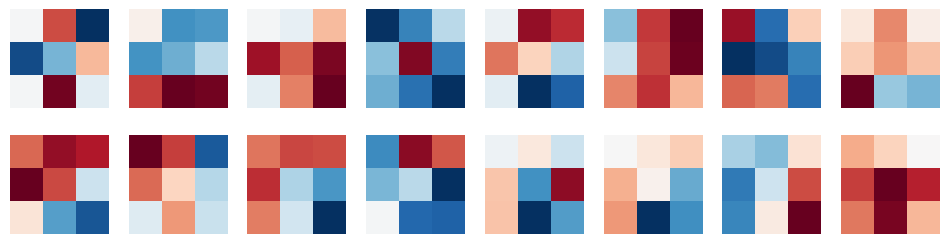

In [34]:
#예제 5-12. 예제 5-11의 best CNN에서 conv1의 kernel
import matplotlib.pyplot as plt
w = model.conv1.weight.detach().cpu() # 학습된 kernel 16개 (16, 1, 3, 3)
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i, ax in enumerate(axes.flat): # 칸 16개를 차례로
 v = w[i, 0].abs().max() # 0이 흰색이 되도록 색 범위를 ±v로
 ax.imshow(w[i, 0], cmap="RdBu_r", vmin=-v, vmax=v)
 ax.axis("off")
plt.show()

In [35]:
#예제 5-14. 모든 사진을 같은 규칙으로 섞는 transform
perm = torch.randperm(784, generator=torch.Generator().manual_seed(123))
def shuffle_pixels(img): # 모든 사진을 같은 규칙으로 섞는다
 return img.view(-1)[perm].view(1, 28, 28)
tf = transforms.Compose([transforms.ToTensor(), shuffle_pixels])
train_all_s = datasets.MNIST(root="data", train=True, download=True,
 transform=tf)
g = torch.Generator().manual_seed(0) # 같은 분리
train_s, val_s = random_split(train_all_s, [50000, 10000], generator=g)
train_loader_s = DataLoader(train_s, batch_size=64, shuffle=True)
val_loader_s = DataLoader(val_s, batch_size=256, shuffle=False)
print(train_set[0][1], train_s[0][1]) # → (예) 9 9 같은 사진, 같은 라벨

9 9


In [36]:
#실습 5. 정답 예시, MLP (CNN은 모델 줄과 파일 이름만 다시 바꿈)
torch.manual_seed(0)
model = MLP().to(device) # 바꾼 곳 1, 모델
opt = torch.optim.SGD(model.parameters(), lr=0.1)
best_acc, best_epoch = 0.0, 0
for epoch in range(10):
 train_one_epoch(model, train_loader_s, opt) # 바꾼 곳 2
 vl, va = evaluate(model, val_loader_s) # 바꾼 곳 3
 print(epoch + 1, round(va, 2))
 if va > best_acc:
    best_acc, best_epoch = va, epoch + 1
    torch.save(model.state_dict(), "shuffled_mlp.pt") # 바꾼 곳 4
print(best_epoch, round(best_acc, 2)) # → (예) 10 97.19

1 90.05
2 93.83
3 94.81
4 95.56
5 95.92
6 96.45
7 96.62
8 97.12
9 97.02
10 97.21
10 97.21
